## Step 1 : Setup
This section is meant for setting up variables, initalizing our quantum circuit and any additional parameters required for hashing

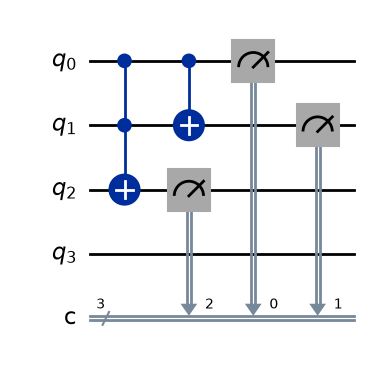

In [14]:
from qiskit import QuantumCircuit
from qiskit.circuit.classical import expr, types
from qiskit_aer.primitives import SamplerV2

coin_positions = ("000", "001", "010", "011", "100", "101", "110", "111")
test = "1001"
size_q = 4

qc = QuantumCircuit(size_q, 3)

for qtarget in range(size_q - 2, 0, -1):
    control = list(range(qtarget))
    qc.mcx(control, qtarget)   
    
qcoin = QuantumCircuit(1)
qcoin.h(0)
qcoin.measure_all()

sampler = SamplerV2()
job = sampler.run([qcoin], shots=1000)

results = job.result()
counts = results[0].data.meas.get_counts()

if counts['1'] > counts['0']:
    qc.mcx([0], 3)

qc.measure([0,1,2], [0,1,2])
qc.draw("mpl")

{4: 1.0}


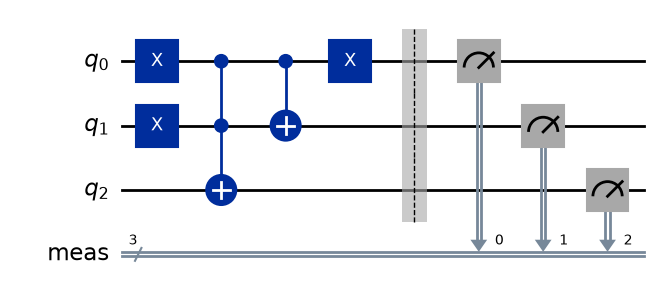

In [52]:
from qiskit import QuantumCircuit
from qiskit_aer.primitives import Sampler

qbit_size = 3
increment = QuantumCircuit(qbit_size)

def shift_right(qbit_size) -> QuantumCircuit:
    inc = QuantumCircuit(qbit_size, name="inc")
    for target in range(qbit_size - 1, 0, -1):
        control = list(range(target))
        inc.mcx(control, target)
    inc.x(0)
    return inc

increment.x(0)
increment.x(1)

increment.compose(shift_right(qbit_size), inplace=True)

increment.measure_all()

sampler = Sampler()
job = sampler.run([increment], shots=1000)
results = job.result()

print(results.quasi_dists[0])

increment.draw("mpl")


In [ ]:
for target in range(2, 0, -1):
    control = list(range(target))
    increment.mcx(control, target)

{2: 1.0}


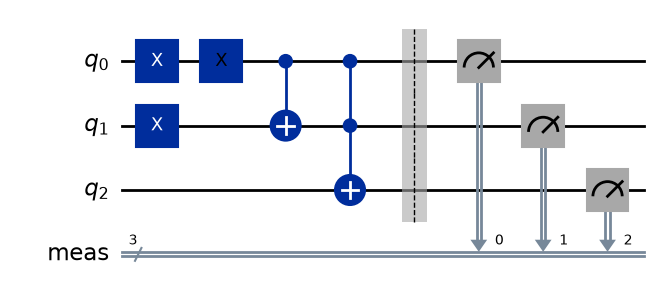

In [56]:
decrement = QuantumCircuit(3)

def shift_left(qbit_size) -> QuantumCircuit:
    dec = QuantumCircuit(qbit_size)
    for target in range(0, 3, +1):
        control = list(range(target))
        dec.mcx(control, target)
    return dec

decrement.x(0)
decrement.x(1)

decrement.compose(shift_left(qbit_size), inplace=True)

decrement.measure_all()

sampler = Sampler()
job = sampler.run([decrement], shots=1000)
results = job.result()

print(results.quasi_dists[0])

decrement.draw("mpl")

## Step 2: Hashing Algorithm

## Step 3: Results